=== TABLE 3: GROUP SIZE (k = 1, 2, 4, 8) & WITNESS REUSE ABLATION ===
      Dataset Group Size k   Kept Size Naive Calls (No Witness) Guided Calls (With Witness)  Calls Saved Call Reduction  Runtime (ms)
breast-cancer k = 1 (Grad) 5.53 ± 1.38              9.00 ± 0.00                 9.00 ± 0.00  0.00 ± 0.00          -0.0%   62.8 ± 19.1
breast-cancer        k = 2 5.53 ± 1.38             15.97 ± 2.57                 5.87 ± 0.70 10.10 ± 2.72         -34.8%   45.6 ± 12.8
breast-cancer        k = 4 5.53 ± 1.38             17.53 ± 3.36                 4.77 ± 0.65 12.77 ± 3.32         -47.0%   40.1 ± 14.6
breast-cancer        k = 8 5.53 ± 1.38             18.53 ± 3.36                 3.97 ± 0.66 14.57 ± 3.72         -55.9%   31.9 ± 15.4
heart-statlog k = 1 (Grad) 6.30 ± 1.33             13.00 ± 0.00                13.00 ± 0.00  0.00 ± 0.00          -0.0% 240.2 ± 199.6
heart-statlog        k = 2 6.30 ± 1.33             20.37 ± 3.29                 8.83 ± 1.20 11.53 ± 2.66         -32.1% 188.4 

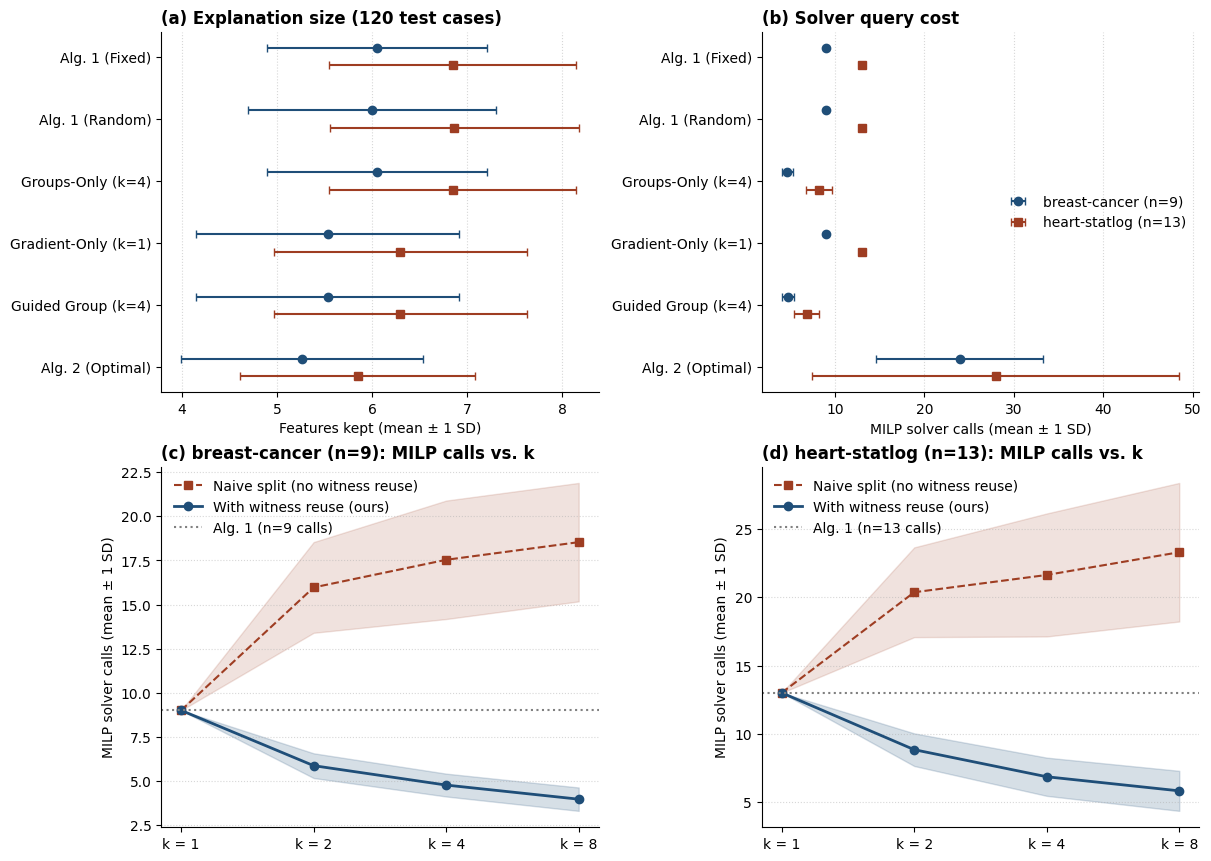

In [ ]:
# For all the tables
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

if "results_df" not in globals():
    results_df = pd.read_csv("replicated_120_cases_results.csv")
    for col in ["fixed_set", "guided_k4_set", "opt_set"]:
        results_df[col] = results_df[col].apply(ast.literal_eval)

# ------------------------------------------------------------------------------
# 1. PRINT TABLE 3: GROUP SIZE k in {1, 2, 4, 8} & WITNESS REUSE ABLATION
# ------------------------------------------------------------------------------
table3_rows = []
for ds_name in ["breast-cancer", "heart-statlog"]:
    sub = results_df[results_df.dataset == ds_name]
    n_feat = int(sub["num_features"].iloc[0])
    s = sub["grad_size"].to_numpy()

    for k in [1, 2, 4, 8]:
        if k == 1:
            naive_c = sub["grad_calls"].to_numpy()
            guided_c = sub["grad_calls"].to_numpy()
            run_t = sub["grad_runtime_ms"].to_numpy()
            label = "k = 1 (Grad)"
        else:
            naive_c = sub[f"naive_k{k}_calls"].to_numpy()
            guided_c = sub[f"guided_k{k}_calls"].to_numpy()
            run_t = sub[f"guided_k{k}_runtime_ms"].to_numpy()
            label = f"k = {k}"

        saved = naive_c - guided_c
        red_pct = (1.0 - guided_c.mean() / n_feat) * 100.0
        table3_rows.append({
            "Dataset": ds_name,
            "Group Size k": label,
            "Kept Size": f"{s.mean():.2f} ± {s.std(ddof=1):.2f}",
            "Naive Calls (No Witness)": f"{naive_c.mean():.2f} ± {naive_c.std(ddof=1):.2f}",
            "Guided Calls (With Witness)": f"{guided_c.mean():.2f} ± {guided_c.std(ddof=1):.2f}",
            "Calls Saved": f"{saved.mean():.2f} ± {saved.std(ddof=1):.2f}",
            "Call Reduction": f"-{red_pct:.1f}%",
            "Runtime (ms)": f"{run_t.mean():.1f} ± {run_t.std(ddof=1):.1f}",
        })

print("=== TABLE 3: GROUP SIZE (k = 1, 2, 4, 8) & WITNESS REUSE ABLATION ===")
print(pd.DataFrame(table3_rows).to_string(index=False))

# ------------------------------------------------------------------------------
# 2. PRINT TABLE 4: CLINICAL FEATURE RETENTION & COLUMN-ORDER BIAS
# ------------------------------------------------------------------------------
selected_features = {
    "breast-cancer": [(0, "clump_thickness (j=0, early)"), (5, "bare_nuclei (j=5, mid)"), (6, "bland_chromatin (j=6, late)")],
    "heart-statlog": [(2, "chest_pain (j=2, early)"), (7, "max_heart_rate (j=7, mid)"), (10, "st_slope (j=10, late)")],
}
table4_rows = []
for ds_name, feat_list in selected_features.items():
    sub = results_df[results_df.dataset == ds_name]
    for j_idx, feat_label in feat_list:
        fix_pct = np.mean([j_idx in st for st in sub["fixed_set"]]) * 100.0
        gui_pct = np.mean([j_idx in st for st in sub["guided_k4_set"]]) * 100.0
        opt_pct = np.mean([j_idx in st for st in sub["opt_set"]]) * 100.0
        table4_rows.append({
            "Dataset": ds_name,
            "Feature (Column Index j)": feat_label,
            "Alg. 1 Fixed": f"{fix_pct:.1f}%",
            "Guided (k=4)": f"{gui_pct:.1f}%",
            "Alg. 2 Optimal": f"{opt_pct:.1f}%",
            "|Fixed - Opt| (Bias)": f"{abs(fix_pct - opt_pct):.1f}%",
            "|Guided - Opt| (Bias)": f"{abs(gui_pct - opt_pct):.1f}%",
        })

print("\n=== TABLE 4: CLINICAL FEATURE RETENTION & COLUMN-ORDER BIAS ===")
print(pd.DataFrame(table4_rows).to_string(index=False))

# ------------------------------------------------------------------------------
# 3. PRINT WILCOXON SIGNED-RANK TESTS (SECTION 4)
# ------------------------------------------------------------------------------
print("\n=== PAIRED WILCOXON SIGNED-RANK TESTS ===")
for ds_name in ["breast-cancer", "heart-statlog"]:
    sub = results_df[results_df.dataset == ds_name]
    diff_size = sub["fixed_size"].to_numpy() - sub["grad_size"].to_numpy()
    p_size = wilcoxon(diff_size).pvalue
    wins = int(np.sum(diff_size > 0))
    ties = int(np.sum(diff_size == 0))
    losses = int(np.sum(diff_size < 0))

    diff_calls = sub["grad_calls"].to_numpy() - sub["guided_k4_calls"].to_numpy()
    p_calls = wilcoxon(diff_calls).pvalue
    print(
        f"{ds_name}: Size (Fixed vs Guided) p = {p_size:.6g} "
        f"(wins={wins}, ties={ties}, losses={losses}) | "
        f"Calls (k=1 vs k=4) p = {p_calls:.6g}"
    )

# ------------------------------------------------------------------------------
# 4. GENERATE FIGURES 2, 3, AND 4
# ------------------------------------------------------------------------------
colors = {"breast-cancer": "#1f4e78", "heart-statlog": "#9e3d22"}

# Figure 2 & Figure 4 combined 4-panel summary plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), constrained_layout=True)

methods_order = [
    ("fixed", "Alg. 1 (Fixed)"),
    ("random", "Alg. 1 (Random)"),
    ("groups_k4", "Groups-Only (k=4)"),
    ("grad", "Gradient-Only (k=1)"),
    ("guided_k4", "Guided Group (k=4)"),
    ("opt", "Alg. 2 (Optimal)"),
]

for d_idx, ds_name in enumerate(["breast-cancer", "heart-statlog"]):
    sub = results_df[results_df.dataset == ds_name]
    n_f = int(sub["num_features"].iloc[0])
    offset = -0.14 if d_idx == 0 else 0.14
    marker = "o" if d_idx == 0 else "s"
    for m_idx, (m_key, _) in enumerate(methods_order):
        sz = sub[f"{m_key}_size"].to_numpy()
        cl = sub[f"{m_key}_calls"].to_numpy()
        axes[0, 0].errorbar(
            sz.mean(), m_idx + offset, xerr=sz.std(ddof=1),
            fmt=marker, color=colors[ds_name], capsize=3,
            label=f"{ds_name} (n={n_f})" if m_idx == 0 else None
        )
        axes[0, 1].errorbar(
            cl.mean(), m_idx + offset, xerr=cl.std(ddof=1),
            fmt=marker, color=colors[ds_name], capsize=3,
            label=f"{ds_name} (n={n_f})" if m_idx == 0 else None
        )

for ax_i, title_str, x_lbl in [
    (0, "(a) Explanation size (120 test cases)", "Features kept (mean ± 1 SD)"),
    (1, "(b) Solver query cost", "MILP solver calls (mean ± 1 SD)"),
]:
    axes[0, ax_i].set_yticks(range(len(methods_order)))
    axes[0, ax_i].set_yticklabels([m[1] for m in methods_order])
    axes[0, ax_i].invert_yaxis()
    axes[0, ax_i].set_title(title_str, fontweight="bold", loc="left")
    axes[0, ax_i].set_xlabel(x_lbl)
    axes[0, ax_i].spines["top"].set_visible(False)
    axes[0, ax_i].spines["right"].set_visible(False)
    axes[0, ax_i].grid(axis="x", linestyle=":", alpha=0.5)
axes[0, 1].legend(frameon=False, loc="center right")

# Bottom row: Group size sensitivity k in {1, 2, 4, 8}
for d_idx, ds_name in enumerate(["breast-cancer", "heart-statlog"]):
    ax = axes[1, d_idx]
    sub = results_df[results_df.dataset == ds_name]
    n_f = int(sub["num_features"].iloc[0])
    x_pos = np.arange(4)

    guided_means, guided_stds = [], []
    naive_means, naive_stds = [], []
    for k in [1, 2, 4, 8]:
        g_vals = sub["grad_calls"].to_numpy() if k == 1 else sub[f"guided_k{k}_calls"].to_numpy()
        n_vals = sub["grad_calls"].to_numpy() if k == 1 else sub[f"naive_k{k}_calls"].to_numpy()
        guided_means.append(g_vals.mean())
        guided_stds.append(g_vals.std(ddof=1))
        naive_means.append(n_vals.mean())
        naive_stds.append(n_vals.std(ddof=1))

    guided_means, guided_stds = np.array(guided_means), np.array(guided_stds)
    naive_means, naive_stds = np.array(naive_means), np.array(naive_stds)

    ax.plot(x_pos, naive_means, "s--", color="#9e3d22", label="Naive split (no witness reuse)")
    ax.fill_between(x_pos, naive_means - naive_stds, naive_means + naive_stds, color="#9e3d22", alpha=0.15)
    ax.plot(x_pos, guided_means, "o-", color="#1f4e78", linewidth=2, label="With witness reuse (ours)")
    ax.fill_between(x_pos, guided_means - guided_stds, guided_means + guided_stds, color="#1f4e78", alpha=0.18)
    ax.axhline(n_f, linestyle=":", color="gray", label=f"Alg. 1 (n={n_f} calls)")

    panel_letter = "(c)" if d_idx == 0 else "(d)"
    ax.set_title(f"{panel_letter} {ds_name} (n={n_f}): MILP calls vs. k", fontweight="bold", loc="left")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(["k = 1", "k = 2", "k = 4", "k = 8"])
    ax.set_ylabel("MILP solver calls (mean ± 1 SD)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.legend(frameon=False, loc="upper left")

plt.savefig("colab_replicated_figures.png", dpi=200)
plt.show()

In [1]:
import os
import time
import json
import urllib.request
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.stats import wilcoxon

# ==============================================================================
# 1. DOWNLOAD AND PARSE UCI DATASETS
# ==============================================================================

def download_and_prepare_uci_datasets(cache_directory="./uci_data"):
    os.makedirs(cache_directory, exist_ok=True)
    datasets = {}

    # 1A. UCI Breast Cancer Wisconsin (Original) - 683 complete rows, 9 features
    bc_url = (
        "https://archive.ics.uci.edu/ml/machine-learning-databases/"
        "breast-cancer-wisconsin/breast-cancer-wisconsin.data"
    )
    bc_filepath = os.path.join(cache_directory, "breast-cancer-wisconsin.data")
    if not os.path.exists(bc_filepath):
        urllib.request.urlretrieve(bc_url, bc_filepath)

    bc_feature_names = [
        "clump_thickness", "cell_size_uniformity", "cell_shape_uniformity",
        "marginal_adhesion", "single_epi_cell_size", "bare_nuclei",
        "bland_chromatin", "normal_nucleoli", "mitoses",
    ]
    bc_rows, bc_labels = [], []
    with open(bc_filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.split(",")
            feat_tokens, cls_token = tokens[1:10], tokens[10]
            if "?" in feat_tokens:
                continue
            bc_rows.append([float(v) for v in feat_tokens])
            bc_labels.append(1 if int(cls_token) == 4 else 0)

    bc_X = np.array(bc_rows, dtype=np.float64)
    datasets["breast-cancer"] = {
        "features": bc_X,
        "labels": np.array(bc_labels, dtype=np.int64),
        "feature_names": bc_feature_names,
        "lower_bounds": np.min(bc_X, axis=0),
        "upper_bounds": np.max(bc_X, axis=0),
    }

    # 1B. UCI Statlog (Heart) - 270 rows, 13 features
    heart_url = (
        "https://archive.ics.uci.edu/ml/machine-learning-databases/"
        "statlog/heart/heart.dat"
    )
    heart_filepath = os.path.join(cache_directory, "heart.dat")
    if not os.path.exists(heart_filepath):
        urllib.request.urlretrieve(heart_url, heart_filepath)

    heart_feature_names = [
        "age", "sex", "chest_pain", "resting_bp", "cholesterol",
        "fasting_blood_sugar", "resting_ecg", "max_heart_rate",
        "exercise_angina", "oldpeak", "st_slope", "major_vessels", "thal",
    ]
    heart_rows, heart_labels = [], []
    with open(heart_filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.split()
            heart_rows.append([float(v) for v in tokens[:13]])
            heart_labels.append(1 if int(float(tokens[13])) == 2 else 0)

    heart_X = np.array(heart_rows, dtype=np.float64)
    datasets["heart-statlog"] = {
        "features": heart_X,
        "labels": np.array(heart_labels, dtype=np.int64),
        "feature_names": heart_feature_names,
        "lower_bounds": np.min(heart_X, axis=0),
        "upper_bounds": np.max(heart_X, axis=0),
    }
    return datasets


# ==============================================================================
# 2. ONE-HIDDEN-LAYER ReLU NETWORK TRAINING (WITH EXACT WEIGHT FOLDING)
# ==============================================================================

def forward_pass_single_instance(network_model, x_vector):
    hidden_pre = np.dot(network_model["W1"], x_vector) + network_model["b1"]
    hidden_act = np.maximum(0.0, hidden_pre)
    logits = np.dot(network_model["W2"], hidden_act) + network_model["b2"]
    predicted_class = 1 if logits[1] >= logits[0] else 0
    return predicted_class, logits


def class_margin(network_model, x_vector, predicted_class):
    _, logits = forward_pass_single_instance(network_model, x_vector)
    return float(logits[predicted_class] - logits[1 - predicted_class])


def train_one_hidden_layer_relu_network(
    X_all, y_all, lower_bounds, upper_bounds, random_seed,
    num_hidden_neurons=15, learning_rate=0.05, l2_penalty=1e-4, num_epochs=1200
):
    rng = np.random.RandomState(random_seed)
    num_samples, num_features = X_all.shape

    shuffled_indices = rng.permutation(num_samples)
    split_point = int(0.80 * num_samples)
    train_idx = shuffled_indices[:split_point]
    test_idx = shuffled_indices[split_point:]

    X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
    X_test_raw, y_test = X_all[test_idx], y_all[test_idx]

    spans = np.where(upper_bounds > lower_bounds, upper_bounds - lower_bounds, 1.0)
    X_train_norm = (X_train_raw - lower_bounds) / spans

    W1_norm = rng.randn(num_hidden_neurons, num_features) * np.sqrt(2.0 / num_features)
    b1_norm = np.zeros(num_hidden_neurons, dtype=np.float64)
    W2 = rng.randn(2, num_hidden_neurons) * np.sqrt(2.0 / num_hidden_neurons)
    b2 = np.zeros(2, dtype=np.float64)

    num_train = X_train_norm.shape[0]
    for _ in range(num_epochs):
        hidden_pre = np.dot(X_train_norm, W1_norm.T) + b1_norm
        hidden_act = np.maximum(0.0, hidden_pre)
        logits = np.dot(hidden_act, W2.T) + b2

        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_l = np.exp(shifted)
        probs = exp_l / np.sum(exp_l, axis=1, keepdims=True)

        d_logits = probs.copy()
        d_logits[np.arange(num_train), y_train] -= 1.0
        d_logits /= float(num_train)

        grad_W2 = np.dot(d_logits.T, hidden_act) + l2_penalty * W2
        grad_b2 = np.sum(d_logits, axis=0)

        d_hidden = np.dot(d_logits, W2) * (hidden_pre > 0.0).astype(np.float64)
        grad_W1 = np.dot(d_hidden.T, X_train_norm) + l2_penalty * W1_norm
        grad_b1 = np.sum(d_hidden, axis=0)

        W2 -= learning_rate * grad_W2
        b2 -= learning_rate * grad_b2
        W1_norm -= learning_rate * grad_W1
        b1_norm -= learning_rate * grad_b1

    # Fold [0, 1] normalization into Layer 1 weights and biases
    W1_raw = W1_norm / spans[np.newaxis, :]
    b1_raw = b1_norm - np.dot(W1_raw, lower_bounds)

    model = {
        "W1": W1_raw, "b1": b1_raw, "W2": W2, "b2": b2,
        "num_inputs": num_features, "num_hidden": num_hidden_neurons,
        "lower_bounds": lower_bounds.copy(), "upper_bounds": upper_bounds.copy(),
    }

    correct_indices = []
    for idx in range(X_test_raw.shape[0]):
        pred, _ = forward_pass_single_instance(model, X_test_raw[idx])
        if pred == int(y_test[idx]):
            correct_indices.append(idx)

    test_acc = len(correct_indices) / float(X_test_raw.shape[0])
    return model, X_test_raw, y_test, correct_indices, test_acc


# ==============================================================================
# 3. EXACT MILP ENTAILMENT ORACLE
# ==============================================================================

def check_entailment_with_milp(
    model, x_star, predicted_class, fixed_subset, time_limit_seconds=60.0
):
    t0 = time.perf_counter()
    W1, b1, W2, b2 = model["W1"], model["b1"], model["W2"], model["b2"]
    L, U = model["lower_bounds"], model["upper_bounds"]
    n, m = model["num_inputs"], model["num_hidden"]
    c = int(predicted_class)
    other = 1 - c

    fixed = set(int(j) for j in fixed_subset)
    x_low = L.copy()
    x_high = U.copy()
    for j in fixed:
        x_low[j] = x_star[j]
        x_high[j] = x_star[j]

    pre_lower = b1.copy()
    pre_upper = b1.copy()
    for i in range(m):
        for j in range(n):
            a = W1[i, j] * x_low[j]
            b = W1[i, j] * x_high[j]
            pre_lower[i] += min(a, b)
            pre_upper[i] += max(a, b)

    M_plus = np.maximum(0.0, pre_upper) + 1.0
    M_minus = np.maximum(0.0, -pre_lower) + 1.0

    total = n + 3 * m
    lower = np.zeros(total)
    upper = np.zeros(total)
    integrality = np.zeros(total, dtype=int)

    lower[:n] = x_low
    upper[:n] = x_high
    upper[n:n + m] = M_plus
    upper[n + m:n + 2 * m] = M_minus
    upper[n + 2 * m:] = 1.0
    integrality[n + 2 * m:] = 1

    objective = np.zeros(total)
    objective[n:n + m] = W2[c] - W2[other]

    rows = 3 * m + 1
    A = np.zeros((rows, total))
    row_lower = np.full(rows, -np.inf)
    row_upper = np.zeros(rows)

    for i in range(m):
        A[i, :n] = W1[i]
        A[i, n + i] = -1.0
        A[i, n + m + i] = 1.0
        row_lower[i] = -b1[i]
        row_upper[i] = -b1[i]

        A[m + i, n + i] = 1.0
        A[m + i, n + 2 * m + i] = M_plus[i]
        row_upper[m + i] = M_plus[i]

        A[2 * m + i, n + m + i] = 1.0
        A[2 * m + i, n + 2 * m + i] = -M_minus[i]
        row_upper[2 * m + i] = 0.0

    A[3 * m, n:n + m] = W2[c] - W2[other]
    row_upper[3 * m] = b2[other] - b2[c]

    res = milp(
        c=objective,
        integrality=integrality,
        bounds=Bounds(lower, upper),
        constraints=LinearConstraint(A, row_lower, row_upper),
        options={"presolve": True, "time_limit": float(time_limit_seconds), "mip_rel_gap": 0.0},
    )
    elapsed = time.perf_counter() - t0

    if res.status == 2:
        return {"status": "UNSAT", "counterexample": None, "elapsed_seconds": elapsed}
    if res.status == 0 and res.x is not None:
        x_ce = np.asarray(res.x[:n], dtype=float)
        return {"status": "SAT", "counterexample": x_ce, "elapsed_seconds": elapsed}
    raise RuntimeError(f"MILP unresolved: status={res.status}, message={res.message}")


# ==============================================================================
# 4. ALGORITHMS 1, 2 (WITH CONFLICT SHRINKING), AND GUIDED GROUP DELETION
# ==============================================================================

def run_sequential(model, x_star, c, order):
    t0 = time.perf_counter()
    kept = list(range(model["num_inputs"]))
    calls = 0
    for j in order:
        cand = [i for i in kept if i != j]
        out = check_entailment_with_milp(model, x_star, c, cand)
        calls += 1
        if out["status"] == "UNSAT":
            kept = cand
    return {
        "explanation": sorted(kept),
        "size": len(kept),
        "milp_calls": calls,
        "runtime_ms": (time.perf_counter() - t0) * 1000.0,
    }


def shrink_conflict_by_forward_pass(model, x_star, c, h_fixed, x_ce, order):
    """
    Greedy O(n) forward-pass conflict minimization:
    Because the MILP objective pushes all free features to their box bounds,
    the raw difference {j not in h : x_ce[j] != x_star[j]} is overly wide.
    We test resetting each free feature j back to x_star[j] in a fast forward
    pass; if the counterexample still flips the prediction (margin <= 0), j is
    not needed in the conflict clause. This yields tight conflict clauses in
    zero extra MILP calls and prevents hitting-set explosion.
    """
    current_ce = x_ce.copy()
    fixed_set = set(h_fixed)
    for j in order:
        if j in fixed_set:
            continue
        if abs(current_ce[j] - x_star[j]) <= 1e-9:
            continue
        trial_ce = current_ce.copy()
        trial_ce[j] = x_star[j]
        if class_margin(model, trial_ce, c) <= 1e-9:
            current_ce = trial_ce

    conflict = [
        j for j in range(model["num_inputs"])
        if j not in fixed_set and abs(current_ce[j] - x_star[j]) > 1e-9
    ]
    if not conflict:
        conflict = [j for j in range(model["num_inputs"]) if j not in fixed_set]
    return conflict


def minimum_hitting_set(conflicts, n):
    if not conflicts:
        return []
    A = np.zeros((len(conflicts), n))
    for r, conf in enumerate(conflicts):
        for j in conf:
            A[r, j] = 1.0
    res = milp(
        c=np.ones(n),
        integrality=np.ones(n, dtype=int),
        bounds=Bounds(np.zeros(n), np.ones(n)),
        constraints=LinearConstraint(A, np.ones(len(conflicts)), np.full(len(conflicts), np.inf)),
        options={"mip_rel_gap": 0.0},
    )
    return [j for j in range(n) if res.x[j] > 0.5]


def run_optimal_hitting_set(model, x_star, c):
    t0 = time.perf_counter()
    n = model["num_inputs"]
    grad_ord, _ = gradient_order(model, x_star, c)
    conflicts = []
    calls = 0
    while True:
        h = minimum_hitting_set(conflicts, n)
        out = check_entailment_with_milp(model, x_star, c, h)
        calls += 1
        if out["status"] == "UNSAT":
            return {
                "explanation": sorted(h),
                "size": len(h),
                "milp_calls": calls,
                "runtime_ms": (time.perf_counter() - t0) * 1000.0,
            }
        shrunk_conflict = shrink_conflict_by_forward_pass(
            model, x_star, c, h, out["counterexample"], grad_ord
        )
        conflicts.append(shrunk_conflict)


def gradient_order(model, x_star, c):
    W1, b1, W2 = model["W1"], model["b1"], model["W2"]
    active = (np.dot(W1, x_star) + b1) > 0.0
    margin_weights = W2[c] - W2[1 - c]
    grad = np.dot(margin_weights * active.astype(float), W1)
    scores = np.abs(grad) * (model["upper_bounds"] - model["lower_bounds"])
    order = sorted(range(model["num_inputs"]), key=lambda j: (scores[j], j))
    return order, scores


def can_certify_sat_with_archive(model, x_star, c, fixed_subset, archive):
    fixed_set = set(fixed_subset)
    for witness in archive:
        proj = witness.copy()
        for j in fixed_set:
            proj[j] = x_star[j]
        if class_margin(model, proj, c) <= 1e-9:
            return True
    return False


def run_group_deletion(model, x_star, c, order, k=4, reuse_witness=True):
    t0 = time.perf_counter()
    n = model["num_inputs"]
    kept = list(range(n))
    archive = []
    calls = 0

    def test_block(block, current_kept):
        nonlocal calls
        bset = set(block)
        cand = [j for j in current_kept if j not in bset]
        if reuse_witness and can_certify_sat_with_archive(model, x_star, c, cand, archive):
            status = "SAT"
        else:
            out = check_entailment_with_milp(model, x_star, c, cand)
            calls += 1
            status = out["status"]
            if status == "SAT" and reuse_witness and out["counterexample"] is not None:
                archive.append(out["counterexample"])

        if status == "UNSAT":
            return cand
        if len(block) == 1:
            return current_kept
        mid = len(block) // 2
        after_left = test_block(block[:mid], current_kept)
        return test_block(block[mid:], after_left)

    for start in range(0, n, k):
        kept = test_block(order[start:start + k], kept)

    # Final singleton verification pass (Line 14 of Table 1)
    for j in order:
        if j not in kept:
            continue
        cand = [i for i in kept if i != j]
        if reuse_witness and can_certify_sat_with_archive(model, x_star, c, cand, archive):
            continue
        out = check_entailment_with_milp(model, x_star, c, cand)
        calls += 1
        if out["status"] == "UNSAT":
            kept = cand
        elif out["status"] == "SAT" and reuse_witness and out["counterexample"] is not None:
            archive.append(out["counterexample"])

    return {
        "explanation": sorted(kept),
        "size": len(kept),
        "milp_calls": calls,
        "runtime_ms": (time.perf_counter() - t0) * 1000.0,
    }


# ==============================================================================
# 5. EXECUTE FULL 120-CASE STUDY AND PRINT SUMMARY TABLES
# ==============================================================================

datasets = download_and_prepare_uci_datasets()
records = []

for dataset_name in ["breast-cancer", "heart-statlog"]:
    ds = datasets[dataset_name]
    X, y = ds["features"], ds["labels"]
    L, U = ds["lower_bounds"], ds["upper_bounds"]
    n = X.shape[1]

    for seed in [42, 43, 44]:
        model, X_test, y_test, correct_idx, acc = train_one_hidden_layer_relu_network(
            X, y, L, U, seed
        )
        print(f"{dataset_name} | seed {seed} | test accuracy = {acc*100:.2f}%")
        rng_perm = np.random.RandomState(seed + 1000)

        for case_id, test_i in enumerate(correct_idx[:20]):
            x_star = X_test[test_i]
            c_star, _ = forward_pass_single_instance(model, x_star)

            fixed_ord = list(range(n))
            rand_orders = [list(rng_perm.permutation(n)) for _ in range(5)]
            grad_ord, _ = gradient_order(model, x_star, c_star)

            res_fixed = run_sequential(model, x_star, c_star, fixed_ord)
            res_rands = [run_sequential(model, x_star, c_star, ro) for ro in rand_orders]
            res_grad = run_sequential(model, x_star, c_star, grad_ord)
            res_groups_k4 = run_group_deletion(model, x_star, c_star, fixed_ord, k=4, reuse_witness=True)

            res_guided = {
                k: run_group_deletion(model, x_star, c_star, grad_ord, k=k, reuse_witness=True)
                for k in (2, 4, 8)
            }
            res_naive = {
                k: run_group_deletion(model, x_star, c_star, grad_ord, k=k, reuse_witness=False)
                for k in (2, 4, 8)
            }
            res_opt = run_optimal_hitting_set(model, x_star, c_star)

            assert res_grad["explanation"] == res_guided[2]["explanation"] == res_guided[4]["explanation"] == res_guided[8]["explanation"]

            records.append({
                "dataset": dataset_name, "seed": seed, "case_id": case_id, "num_features": n,
                "fixed_size": res_fixed["size"], "fixed_calls": res_fixed["milp_calls"], "fixed_runtime_ms": res_fixed["runtime_ms"], "fixed_set": res_fixed["explanation"],
                "random_size": res_rands[0]["size"], "random_calls": res_rands[0]["milp_calls"], "random_runtime_ms": res_rands[0]["runtime_ms"],
                "grad_size": res_grad["size"], "grad_calls": res_grad["milp_calls"], "grad_runtime_ms": res_grad["runtime_ms"],
                "groups_k4_size": res_groups_k4["size"], "groups_k4_calls": res_groups_k4["milp_calls"], "groups_k4_runtime_ms": res_groups_k4["runtime_ms"],
                "guided_k2_size": res_guided[2]["size"], "guided_k2_calls": res_guided[2]["milp_calls"], "guided_k2_runtime_ms": res_guided[2]["runtime_ms"],
                "guided_k4_size": res_guided[4]["size"], "guided_k4_calls": res_guided[4]["milp_calls"], "guided_k4_runtime_ms": res_guided[4]["runtime_ms"], "guided_k4_set": res_guided[4]["explanation"],
                "guided_k8_size": res_guided[8]["size"], "guided_k8_calls": res_guided[8]["milp_calls"], "guided_k8_runtime_ms": res_guided[8]["runtime_ms"],
                "naive_k2_calls": res_naive[2]["milp_calls"], "naive_k4_calls": res_naive[4]["milp_calls"], "naive_k8_calls": res_naive[8]["milp_calls"],
                "opt_size": res_opt["size"], "opt_calls": res_opt["milp_calls"], "opt_runtime_ms": res_opt["runtime_ms"], "opt_set": res_opt["explanation"],
            })

results_df = pd.DataFrame(records)
results_df.to_csv("replicated_120_cases_results.csv", index=False)

# Print Summary Table (Table 2 format)
summary_rows = []
for ds_name in ["breast-cancer", "heart-statlog"]:
    sub = results_df[results_df.dataset == ds_name]
    opt_s = sub["opt_size"].to_numpy()
    for m_key, m_label in [
        ("fixed", "Alg. 1 (Fixed)"),
        ("random", "Alg. 1 (Random)"),
        ("grad", "Gradient-Only (k=1)"),
        ("groups_k4", "Groups-Only (k=4)"),
        ("guided_k4", "Guided Group (k=4)"),
        ("opt", "Alg. 2 (Optimal)"),
    ]:
        s = sub[f"{m_key}_size"].to_numpy()
        c = sub[f"{m_key}_calls"].to_numpy()
        t = sub[f"{m_key}_runtime_ms"].to_numpy()
        summary_rows.append({
            "Dataset": ds_name,
            "Method": m_label,
            "Kept Size": f"{s.mean():.2f} ± {s.std(ddof=1):.2f}",
            "Opt Match (%)": f"{np.mean(s == opt_s)*100:.1f}%",
            "Gap to Opt": f"+{np.mean(s - opt_s):.2f}",
            "MILP Calls": f"{c.mean():.2f} ± {c.std(ddof=1):.2f}",
            "Runtime (ms)": f"{t.mean():.1f} ± {t.std(ddof=1):.1f}",
        })

print("\n=== TABLE 2: MAIN BENCHMARK RESULTS (120 CASES) ===")
print(pd.DataFrame(summary_rows).to_string(index=False))

breast-cancer | seed 42 | test accuracy = 95.62%
breast-cancer | seed 43 | test accuracy = 99.27%
breast-cancer | seed 44 | test accuracy = 95.62%
heart-statlog | seed 42 | test accuracy = 77.78%
heart-statlog | seed 43 | test accuracy = 77.78%
heart-statlog | seed 44 | test accuracy = 83.33%

=== TABLE 2: MAIN BENCHMARK RESULTS (120 CASES) ===
      Dataset              Method   Kept Size Opt Match (%) Gap to Opt    MILP Calls    Runtime (ms)
breast-cancer      Alg. 1 (Fixed) 6.05 ± 1.16         31.7%      +0.78   9.00 ± 0.00     83.4 ± 42.9
breast-cancer     Alg. 1 (Random) 6.00 ± 1.30         33.3%      +0.73   9.00 ± 0.00     79.5 ± 36.4
breast-cancer Gradient-Only (k=1) 5.53 ± 1.38         78.3%      +0.27   9.00 ± 0.00     88.4 ± 40.5
breast-cancer   Groups-Only (k=4) 6.05 ± 1.16         31.7%      +0.78   4.70 ± 0.65     61.9 ± 47.5
breast-cancer  Guided Group (k=4) 5.53 ± 1.38         78.3%      +0.27   4.77 ± 0.65     58.0 ± 42.3
breast-cancer    Alg. 2 (Optimal) 5.27 ± 1.27  